<h1 style="color:#8B0000;">CIFAR-10 EDA and data pipeline (SimCLR project)</h1>

<h3 style="color:#8B0000;">Setup</h3>

Imports, seed and data options. CIFAR-10 is downloaded with torchvision, so no extra files are needed. To use the Kaggle copy instead (`trainLabels.csv` and the `train/` folder), set `USE_KAGGLE = True`. Packages are listed in `requirements.txt`.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
import torch
import torchvision
from torchvision import datasets

# torchvision downloads CIFAR-10 here, once
DATA_ROOT = "./data"

# Optional: read the Kaggle copy instead (needs these files next to the notebook)
USE_KAGGLE = False
CSV_PATH = "trainLabels.csv"
TRAIN_DIR = "train"

# Fixed seed, so random results repeat
SEED = 42
np.random.seed(SEED)

<h1 style="color:#8B0000; border-bottom:2px solid #8B0000; padding-bottom:4px;">2. Exploratory Data Analysis</h1>

<h3 style="color:#8B0000;">2.1 Dataset size and class balance</h3>

How many images and classes are there, and are the classes balanced?

Total images: 50000
Number of classes: 10
Images per class:
label
airplane      5000
automobile    5000
bird          5000
cat           5000
deer          5000
dog           5000
frog          5000
horse         5000
ship          5000
truck         5000
Name: count, dtype: int64
Imbalance ratio (largest / smallest): 1.0
Random guessing accuracy: 10%


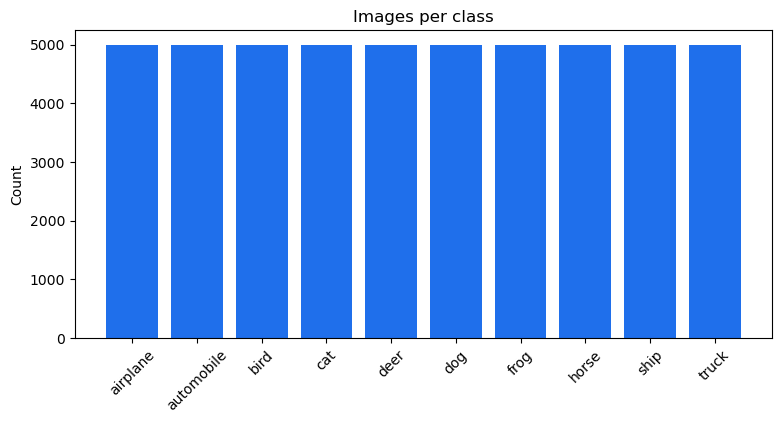

In [4]:
# Load the 50,000 training images into one array X (uint8, 50000 x 32 x 32 x 3)
if USE_KAGGLE:
    df = pd.read_csv(CSV_PATH)
    classes = sorted(df["label"].unique())
    X = np.zeros((len(df), 32, 32, 3), dtype=np.uint8)
    for i in range(len(df)):
        X[i] = np.array(Image.open(TRAIN_DIR + "/" + str(df["id"][i]) + ".png").convert("RGB"))
    y = df["label"].map({name: n for n, name in enumerate(classes)}).values
else:
    train_raw = datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)
    X = train_raw.data                       # uint8, 50000 x 32 x 32 x 3
    y = np.array(train_raw.targets)          # integers 0 to 9
    classes = list(train_raw.classes)        # alphabetical order
    df = pd.DataFrame({"label": [classes[t] for t in y]})

counts = df["label"].value_counts().reindex(classes)

print("Total images:", len(df))
print("Number of classes:", len(classes))
print("Images per class:")
print(counts)
print("Imbalance ratio (largest / smallest):", counts.max() / counts.min())
print("Random guessing accuracy: %.0f%%" % (100 / len(classes)))

plt.figure(figsize=(9, 4))
plt.bar(counts.index, counts.values, color="#1f6feb")
plt.title("Images per class")
plt.xticks(rotation=45)
plt.ylabel("Count")
plt.show()

<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> The training set has 50,000 images in 10 classes, 5,000 per class, so the classes are balanced. Plain accuracy is a fair metric here. Random guessing gets 10%.
</div>

<h3 style="color:#8B0000;">2.2 Check the data is clean</h3>

Check the array shape and the labels, and look for exact duplicate images by hashing the pixels.

In [5]:
import hashlib

print("Array shape and dtype:", X.shape, X.dtype)
print("Labels outside 0-9:", int(((y < 0) | (y > 9)).sum()))
print("Missing labels:", int(df["label"].isnull().sum()))

# Exact duplicates: hash every image and look for repeated hashes
hashes = pd.Series([hashlib.md5(X[i].tobytes()).hexdigest() for i in range(len(X))])
is_dup = hashes.duplicated(keep=False)
print("Images with an exact pixel duplicate:", int(is_dup.sum()))

if is_dup.any():
    # Do duplicates disagree on the label?
    n_labels = pd.DataFrame({"h": hashes, "y": y})[is_dup].groupby("h")["y"].nunique()
    print("Duplicate groups with conflicting labels:", int((n_labels > 1).sum()))

Array shape and dtype: (50000, 32, 32, 3) uint8
Labels outside 0-9: 0
Missing labels: 0
Images with an exact pixel duplicate: 0


<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> The shape, label and duplicate counts are printed above. The hash check only finds exact copies. It does not find near-duplicates (resized or slightly edited copies).
</div>

<h3 style="color:#8B0000;">2.3 Look at the images</h3>

Five random images from each class.

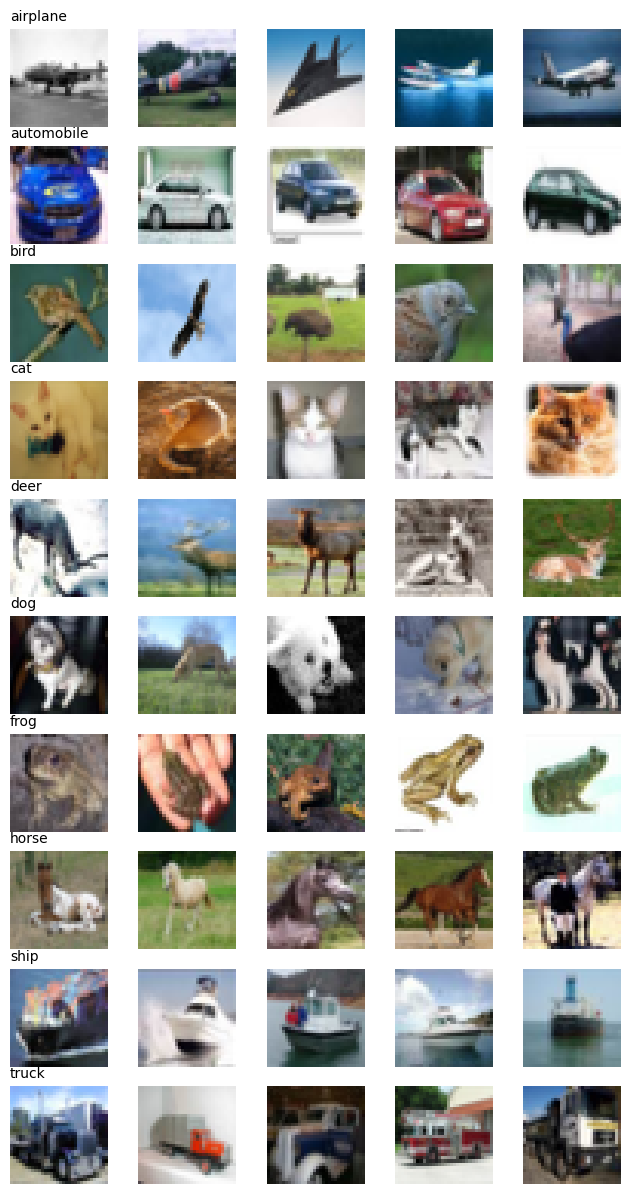

In [6]:
fig, axes = plt.subplots(10, 5, figsize=(8, 15))

for row in range(10):
    ids = np.where(y == row)[0]
    chosen = np.random.choice(ids, 5, replace=False)
    for col in range(5):
        axes[row, col].imshow(X[chosen[col]])
        axes[row, col].axis("off")
    axes[row, 0].set_title(classes[row], loc="left", fontsize=10)

plt.show()

<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> Images of the same class differ a lot in pose, zoom, background and colour. Some classes share a typical background, such as sky for airplanes and water for ships. The images are small (32x32) and low resolution.
</div>

<h3 style="color:#8B0000;">2.4 Pixel statistics</h3>

Pixel range and the mean and std of each colour. We use these to normalise the images in Part 3.

In [7]:
print("Pixel values go from", X.min(), "to", X.max())

mean = X.mean(axis=(0, 1, 2)) / 255
std = X.std(axis=(0, 1, 2)) / 255
print("Mean (R, G, B):", mean.round(3))
print("Std  (R, G, B):", std.round(3))

Pixel values go from 0 to 255
Mean (R, G, B): [0.491 0.482 0.447]
Std  (R, G, B): [0.247 0.243 0.262]


<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> Pixel values go from 0 to 255. The per-channel mean and std are printed above. We use them to normalise the images in Part 3.
</div>

<h3 style="color:#8B0000;">2.5 Brightness and colour by class</h3>

Brightness (average pixel value) and average colour for each class.

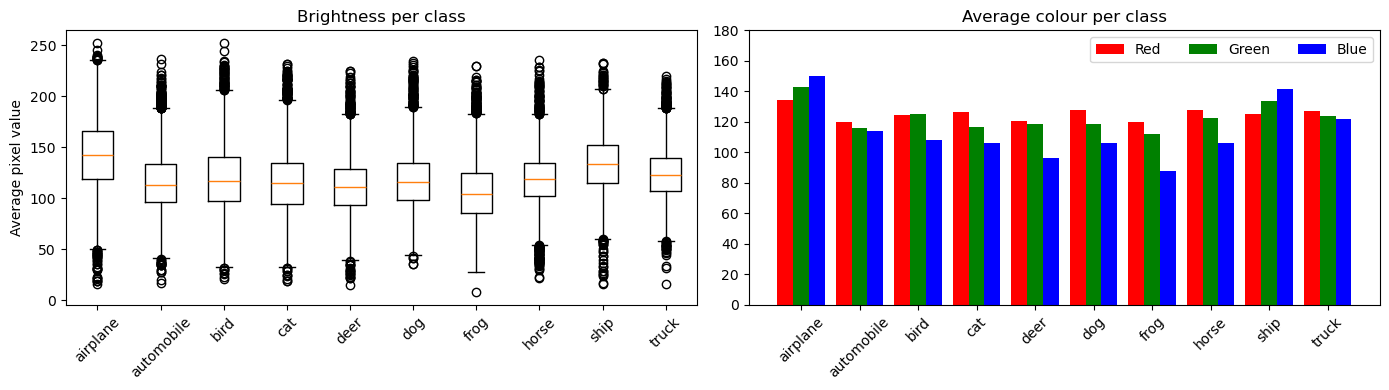

                R      G      B  median brightness
airplane    134.0  142.9  150.2              142.2
automobile  120.2  115.9  114.0              113.0
bird        124.8  125.3  108.1              117.3
cat         126.3  116.4  106.0              115.1
deer        120.3  118.6   96.4              110.8
dog         127.5  118.5  106.2              115.9
frog        119.9  111.8   88.0              104.1
horse       128.0  122.4  106.3              118.9
ship        125.0  134.0  141.4              133.3
truck       127.2  123.8  121.9              122.6

Brightness cut-offs: 38.8 to 200.5
Dark outliers: 162 | bright outliers: 658
Outliers per class:
airplane      288
automobile     53
bird          107
cat            91
deer           47
dog            52
frog           52
horse          45
ship           59
truck          26
dtype: int64
Images with pixel std below 10: 1


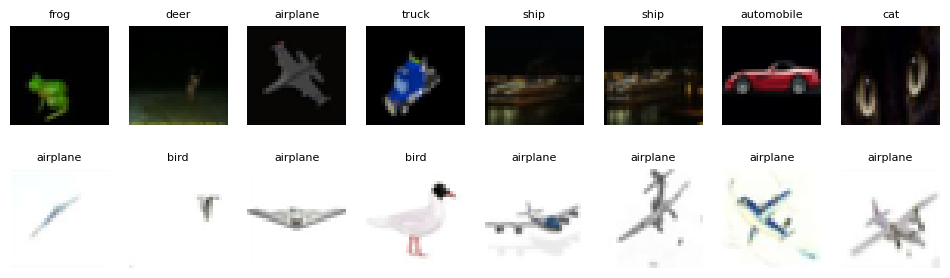

In [8]:
# Brightness of every image
brightness = X.mean(axis=(1, 2, 3))

# Average red, green and blue of each class
colour_means = []
for n in range(10):
    colour_means.append(X[y == n].mean(axis=(0, 1, 2)))
colour_means = np.array(colour_means)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Left: brightness boxplot per class
ax[0].boxplot([brightness[y == n] for n in range(10)])
ax[0].set_xticks(range(1, 11))
ax[0].set_xticklabels(classes, rotation=45)
ax[0].set_title("Brightness per class")
ax[0].set_ylabel("Average pixel value")

# Right: average colour per class
positions = np.arange(10)
ax[1].bar(positions - 0.27, colour_means[:, 0], width=0.27, color="red", label="Red")
ax[1].bar(positions, colour_means[:, 1], width=0.27, color="green", label="Green")
ax[1].bar(positions + 0.27, colour_means[:, 2], width=0.27, color="blue", label="Blue")
ax[1].set_xticks(positions)
ax[1].set_xticklabels(classes, rotation=45)
ax[1].set_ylim(0, 180)
ax[1].legend(loc="upper right", ncol=3)
ax[1].set_title("Average colour per class")

plt.tight_layout()
plt.show()

# Exact numbers
table = pd.DataFrame(colour_means, index=classes, columns=["R", "G", "B"]).round(1)
table["median brightness"] = pd.Series(brightness).groupby(df["label"].values).median().round(1)
print(table)

# Outliers: brightness outside 1.5 x IQR of all images
q1, q3 = np.percentile(brightness, [25, 75])
iqr = q3 - q1
low_cut, high_cut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
too_dark, too_bright = brightness < low_cut, brightness > high_cut
print("\nBrightness cut-offs: %.1f to %.1f" % (low_cut, high_cut))
print("Dark outliers:", int(too_dark.sum()), "| bright outliers:", int(too_bright.sum()))
print("Outliers per class:")
print(pd.Series(too_dark | too_bright).groupby(df["label"].values).sum())

# Images with almost no contrast
contrast = X.std(axis=(1, 2, 3))
print("Images with pixel std below 10:", int((contrast < 10).sum()))

# The 8 darkest (top row) and 8 brightest (bottom row) images
order = np.argsort(brightness)
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for k in range(8):
    ax[0, k].imshow(X[order[k]])
    ax[0, k].set_title(classes[y[order[k]]], fontsize=8)
    ax[1, k].imshow(X[order[-1 - k]])
    ax[1, k].set_title(classes[y[order[-1 - k]]], fontsize=8)
for a in ax.ravel():
    a.axis("off")
plt.show()

<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> In our first run, airplane and ship had the highest median brightness and frog the lowest, and airplane and ship were the only classes where blue was the strongest channel (see the table). Brightness overlaps a lot between classes, but the average colour differs somewhat by class. The paper (Section 3.1) points out that two crops of the same image have a similar colour histogram, so a network can match them by colour alone. Colour jitter and random grayscale are there to prevent that. The outlier counts above show how many images are unusually dark or bright. They are real photos, so we keep them.
</div>

<h3 style="color:#8B0000;">2.6 PCA and a simple baseline</h3>

PCA on 5,000 random images, plotted in 2D, then a basic kNN model on the PCA numbers as a baseline.

In [ ]:
# 5000 random images
np.random.seed(SEED)
pick = np.random.choice(len(X), min(5000, len(X)), replace=False)
pixels = X[pick].reshape(len(pick), -1) / 255
labels = y[pick]

# Split first (80 percent train, 20 percent test), so the PCA never sees the test part
pix_train, pix_test, y_train, y_test = train_test_split(
    pixels, labels, test_size=0.2, stratify=labels, random_state=SEED)

pca = PCA(n_components=50, random_state=SEED).fit(pix_train)
Z_train, Z_test = pca.transform(pix_train), pca.transform(pix_test)
Z = pca.transform(pixels)   # all 5000 points, only for the scatter plot

print("Variance kept by first 2 components: %.1f%%" % (pca.explained_variance_ratio_[:2].sum() * 100))
print("Variance kept by all 50 components : %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))

plt.figure(figsize=(7, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=8, alpha=0.7)
plt.legend(scatter.legend_elements()[0], classes, fontsize=7, bbox_to_anchor=(1, 1))
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("PCA of raw pixels")
plt.show()

# Baseline: kNN on the 50 PCA features
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Z_train, y_train)

print("Random guessing: 10%")
print("kNN accuracy: %.1f%%" % (knn.score(Z_test, y_test) * 100))

<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> The first two PCA components explain only part of the variance (printed above), and the classes overlap in the scatter plot, so raw pixels do not separate them well. The kNN score printed above is our raw-pixel baseline (random is 10%). It is measured on a held-out part of a 5,000-image training sample, not on the official test set, so treat it as a rough reference.
</div>

<h3 style="color:#8B0000;">2.7 Evaluation metrics</h3>

**Main metric:** top-1 accuracy on the official 10,000-image test set, from a linear classifier trained on the frozen encoder. This is the paper's linear evaluation protocol. The classes are balanced, so accuracy is not misleading. Random guessing gives 10%.

**Extra metrics (ours, not from the paper):** per-class precision, recall and F1, macro-F1, and a confusion matrix to see which classes get mixed up.

**Not needed:** top-5 accuracy (only 10 classes) and metrics made for imbalanced data (our classes are balanced).

**Comparison with the paper:** its best CIFAR-10 linear-evaluation result is 94.0% (ResNet-50, batch size 1024, Appendix B.9). Our setup is different (ResNet-18, batch size 256, far fewer epochs), so we expect lower numbers and do not treat 94.0% as a target. In the data-fraction experiment every run is scored on the same test set with the same metrics.

<h3 style="color:#8B0000;">2.8 Challenges and what we do about them</h3>

- Small, low-resolution images with a lot of variety inside each class. We use strong augmentation (3.2).
- Colour differs somewhat by class, so a network could match views by colour alone (paper, Section 3.1). We use colour jitter and random grayscale (3.2).
- Raw pixels separate the classes poorly (PCA plot, kNN baseline), so we need a learned encoder.
- Same-class negatives: with batch size 256 each image has 2 x 255 = 510 negatives (paper, Section 2.1), and in expectation about 10% of them (around 51) are from its own class. The SimCLR paper does not discuss this. Debiased Contrastive Learning (Chuang et al., NeurIPS 2020) does. We will mention it when we discuss results.
- The Kaggle competition test set has no public labels. We use the official CIFAR-10 test set (3.5).
- The data-fraction experiment needs fair subsets. We use stratified sampling with a fixed seed and the same number of training steps for every fraction, because a 1% subset has only 1 batch per epoch at batch size 256 (3.6).

The missing-label and duplicate checks are in 2.2, and the brightness outlier checks are in 2.5.

<h1 style="color:#8B0000; border-bottom:2px solid #8B0000; padding-bottom:4px;">3. Data Loading and Preprocessing Pipeline</h1>

<h3 style="color:#8B0000;">3.1 Environment</h3>

Load PyTorch, pick the device (cuda, mps or cpu), set the seed and the DataLoader settings.

In [10]:
import platform
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms

# Seed torch too, so shuffling and augmentations repeat
torch.manual_seed(SEED)

# Pick the best device available
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# DataLoader settings used by every loader below.
# Linux with CUDA (e.g. Colab): 2 worker processes. Change this to match the CPU cores you have.
# Mac or CPU: 0 workers, because macOS worker processes can fail with classes defined in a notebook.
NUM_WORKERS = 2 if (device.type == "cuda" and platform.system() == "Linux") else 0
LOADER_KWARGS = dict(num_workers=NUM_WORKERS,
                     pin_memory=(device.type == "cuda"),
                     persistent_workers=(NUM_WORKERS > 0))   # only allowed with at least 1 worker

print("torch", torch.__version__, "| torchvision", torchvision.__version__)
print("Device in use:", device, "| DataLoader workers:", NUM_WORKERS)

torch 2.14.1 | torchvision 0.29.1
Device in use: mps | DataLoader workers: 0


<h3 style="color:#8B0000;">3.2 Preprocessing and augmentation</h3>

Normalisation with our own mean and std from 2.4, and the SimCLR augmentations. The crop, colour and grayscale settings follow the paper's CIFAR-10 setup (Appendix A and B.9). Training uses random augmentations. Evaluation only normalises.

In [12]:
# Normalisation values measured in section 2.4
MEAN = tuple(float(v) for v in mean)
STD = tuple(float(v) for v in std)

# Training transform: one random augmented view of an image
simclr_transform = transforms.Compose([
    # Random crop covering 8 to 100 percent of the image area, resized back to 32x32
    transforms.RandomResizedCrop(32, scale=(0.08, 1.0)),
    # Flip left-right half of the time
    transforms.RandomHorizontalFlip(p=0.5),
    # Colour jitter with strength 0.5 (0.8 x 0.5 = 0.4, hue 0.2 x 0.5 = 0.1), applied 80 percent of the time
    transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
    # Turn gray 20 percent of the time
    transforms.RandomGrayscale(p=0.2),
    # Picture to tensor with values between 0 and 1
    transforms.ToTensor(),
    # Centre and scale each colour channel
    transforms.Normalize(MEAN, STD),
])

# Evaluation transform: no augmentation, only normalisation
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

print("Normalisation mean:", [round(v, 3) for v in MEAN])
print("Normalisation std :", [round(v, 3) for v in STD])

Normalisation mean: [0.491, 0.482, 0.447]
Normalisation std : [0.247, 0.243, 0.262]


<h3 style="color:#8B0000;">3.3 Dataset and DataLoader for pretraining</h3>

A dataset that gives two random views of each image (a positive pair), and a DataLoader with batch size 256.

In [13]:
class ArrayDataset(Dataset):
    """Wraps the image array. Gives two views per image if two_views is True, otherwise one view."""

    def __init__(self, images, labels, transform, two_views=False):
        self.images = images
        self.labels = labels
        self.transform = transform
        self.two_views = two_views

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        # Turn the stored array back into a picture so torchvision can augment it
        img = Image.fromarray(self.images[i])
        label = int(self.labels[i])
        if self.two_views:
            # Two independent random augmentations of the same image (a positive pair)
            return self.transform(img), self.transform(img), label
        return self.transform(img), label

# Batch size from our proposal. The paper uses 4096 by default on ImageNet and 256 to 4096 on CIFAR-10.
BATCH_SIZE = 256

pretrain_set = ArrayDataset(X, y, simclr_transform, two_views=True)

# drop_last=True keeps every batch the same size, so every image has the same number of negatives.
# Workers come from LOADER_KWARGS (3.1). Augmentation runs on the CPU and may be the bottleneck.
pretrain_loader = DataLoader(pretrain_set, batch_size=BATCH_SIZE, shuffle=True,
                             drop_last=True, **LOADER_KWARGS)

print("Images:", len(pretrain_set))
print("Batches per epoch:", len(pretrain_loader))

Images: 50000
Batches per epoch: 195


<h3 style="color:#8B0000;">3.4 Check one batch</h3>

Take one batch, check the shapes and values, and look at a few pairs.

View 1 shape: (256, 3, 32, 32)
View 2 shape: (256, 3, 32, 32)
Value range : -1.99 to 2.13


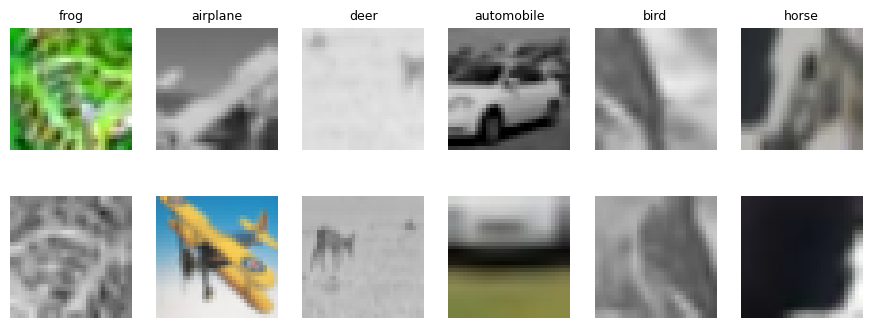

Data loading only: 0.112 s per batch


In [14]:
view1, view2, batch_labels = next(iter(pretrain_loader))

print("View 1 shape:", tuple(view1.shape))
print("View 2 shape:", tuple(view2.shape))
print("Value range : %.2f to %.2f" % (view1.min().item(), view1.max().item()))

# Undo the normalisation so the pictures can be shown
def show(t):
    m = torch.tensor(MEAN).view(3, 1, 1)
    s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for k in range(6):
    axes[0, k].imshow(show(view1[k]))
    axes[1, k].imshow(show(view2[k]))
    axes[0, k].set_title(classes[int(batch_labels[k])], fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.show()

# Data-loading speed with no model: seconds per batch (average over 20 batches)
import time
t0 = time.time()
for i, (v1, v2, _) in enumerate(pretrain_loader):
    if i == 19:
        break
print("Data loading only: %.3f s per batch" % ((time.time() - t0) / 20))

<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> Both views have shape (256, 3, 32, 32). Normalised values are not limited to the range 0 to 1 (the printed range is for one random batch). The two rows show the same images with different random augmentations. The timing line shows data-loading speed without a model. We will use it when we choose the number of epochs.
</div>

<h3 style="color:#8B0000;">3.5 Labelled data for linear evaluation</h3>

After pretraining we train a linear classifier on the frozen encoder, so we need labelled images with no augmentation. The test set is the official 10,000 images. If it cannot be downloaded, we hold out 10% of the training images instead.

In [15]:
# Training images for the linear classifier: no augmentation
train_set = ArrayDataset(X, y, eval_transform)

try:
    # Official labelled test set (downloads once into DATA_ROOT)
    test_set = datasets.CIFAR10(root=DATA_ROOT, train=False, download=True, transform=eval_transform)
    print("Official test set loaded:", len(test_set), "images")
    # Class numbers must match ours (both are in alphabetical order)
    print("Class order matches:", list(test_set.classes) == classes)
except Exception as error:
    # Fallback: hold out 10 percent of the training images, the same share from every class
    print("Could not load the official test set:", error)
    train_idx, test_idx = train_test_split(np.arange(len(X)), test_size=0.1, stratify=y, random_state=SEED)
    test_set = Subset(train_set, test_idx)
    train_set = Subset(train_set, train_idx)
    print("Using a hold-out split instead. Label any results from it as such.")

train_loader = DataLoader(train_set, batch_size=256, shuffle=True, **LOADER_KWARGS)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, **LOADER_KWARGS)

print("Training images:", len(train_set))
print("Test images    :", len(test_set))

Official test set loaded: 10000 images
Class order matches: True
Training images: 50000
Test images    : 10000


<h3 style="color:#8B0000;">3.6 Data-fraction subsets</h3>

A function that picks the same fraction of images from every class, for the data-fraction experiment. The fractions below are examples. The final list depends on our compute. The printout shows the class balance, the mean brightness, the batches per epoch, and how many epochs each fraction needs to reach the same number of training steps (`TOTAL_STEPS`).

In [16]:
import math

def stratified_subset(labels, fraction, seed=SEED):
    """Pick the same fraction of images from every class (at least 1 per class)."""
    rng = np.random.RandomState(seed)
    chosen = []
    for n in range(10):
        ids = np.where(labels == n)[0]
        how_many = max(1, int(len(ids) * fraction))
        chosen.extend(rng.choice(ids, how_many, replace=False))
    return np.array(chosen)

# Every run gets the same number of optimizer steps.
# PLACEHOLDER: 100 epochs of the full set (195 batches each). Replace it with a value
# chosen from the measured training speed on our hardware.
TOTAL_STEPS = (len(X) // BATCH_SIZE) * 100
print("TOTAL_STEPS per run:", TOTAL_STEPS)

print("Full dataset brightness: %.1f" % brightness.mean())
for fraction in [0.01, 0.05, 0.10, 0.25, 0.50, 1.00]:
    idx = stratified_subset(y, fraction)
    per_class = np.bincount(y[idx], minlength=10)
    batches = len(idx) // BATCH_SIZE                  # drop_last=True
    epochs_needed = math.ceil(TOTAL_STEPS / batches)  # epochs needed to reach TOTAL_STEPS
    print("Fraction", fraction, "-> images:", len(idx),
          "| per class:", per_class.min(), "to", per_class.max(),
          "| brightness: %.1f" % brightness[idx].mean(),
          "| batches/epoch:", batches, "| epochs for TOTAL_STEPS:", epochs_needed)

# Example: a pretraining loader on 10 percent of the data.
# In the training loop, stop as soon as the step count reaches TOTAL_STEPS.
subset_loader = DataLoader(Subset(pretrain_set, stratified_subset(y, 0.10)),
                           batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **LOADER_KWARGS)
print("Batches per epoch on 10 percent:", len(subset_loader))

# We reshuffle every epoch instead of sampling with replacement. With a small subset,
# sampling with replacement could put the same image twice in one batch.

TOTAL_STEPS per run: 19500
Full dataset brightness: 120.7
Fraction 0.01 -> images: 500 | per class: 50 to 50 | brightness: 121.8 | batches/epoch: 1 | epochs for TOTAL_STEPS: 19500
Fraction 0.05 -> images: 2500 | per class: 250 to 250 | brightness: 121.3 | batches/epoch: 9 | epochs for TOTAL_STEPS: 2167
Fraction 0.1 -> images: 5000 | per class: 500 to 500 | brightness: 120.9 | batches/epoch: 19 | epochs for TOTAL_STEPS: 1027
Fraction 0.25 -> images: 12500 | per class: 1250 to 1250 | brightness: 120.9 | batches/epoch: 48 | epochs for TOTAL_STEPS: 407
Fraction 0.5 -> images: 25000 | per class: 2500 to 2500 | brightness: 120.8 | batches/epoch: 97 | epochs for TOTAL_STEPS: 202
Fraction 1.0 -> images: 50000 | per class: 5000 to 5000 | brightness: 120.7 | batches/epoch: 195 | epochs for TOTAL_STEPS: 100
Batches per epoch on 10 percent: 19


<div style="border-left:4px solid #8B0000; background:#fbf3f3; color:#222; padding:6px 14px;">
<b>What we see.</b> Every fraction has the same number of images per class, and the mean brightness stays close to the full set (printed above). With batch size 256 and `drop_last=True`, a 1% subset (500 images) has only one batch per epoch, so a fixed number of epochs would give small subsets far fewer updates. We therefore compare runs at the same number of steps. `TOTAL_STEPS` is a placeholder until we have measured training speed. Matching steps repeats small subsets many times, which has its own effect. If compute allows, a fixed-epoch run could be added as a comparison.
</div>

<h3 style="color:#8B0000;">3.7 What we changed from the paper and the official code</h3>

The official code is in TensorFlow and the paper trained on Cloud TPUs. We only use them as a reference. This pipeline is our own PyTorch code.

**Same as the paper (CIFAR-10, Appendix A and B.9):** random crop of 8 to 100% of the area, random flip, colour jitter at strength 0.5 (applied 80% of the time), grayscale 20% of the time, no Gaussian blur. The jitter and grayscale values follow the PyTorch snippet in Appendix A. The official TensorFlow code may differ in details.

**Different:**
- PyTorch instead of TensorFlow, so it runs on Colab or a laptop.
- Batch size 256 (our proposal). The paper's CIFAR-10 runs use 256 to 4096.
- The official train and test sets are loaded through torchvision. The Kaggle copy is optional.
- The linear classifier is trained on normalised images without augmentation. For ImageNet, the paper's Appendix B.6 says linear evaluation follows the fine-tuning procedure of B.5, which uses random crop and flip. B.9 does not say what was used for CIFAR-10.
- The data-fraction runs are matched on training steps (3.6). This experiment is not in the paper.

**Not built yet (from our proposal):**
- ResNet-18 adapted to 32x32 images. The paper's B.9 uses ResNet-50 with a 3x3 stride-1 first convolution and no first max-pool, and we plan the same stem change.
- SGD or Adam, chosen after pilot runs. The paper uses LARS.
- Fewer epochs than the paper, decided from our compute (see the loading-speed check in 3.4).

We will update this list once the training code exists.